In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pickle
import math
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

In [2]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
np_file = np.load(filename)
cycle1_dhs_arr = np_file['new_dhs_array']

cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [3]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

biosample_df['Replicate indicators'] = biosample_df['Replicate indicators'].astype(str)

In [4]:
#find replicates
biosamples_repnames = np.array(biosample_df['Replicate indicators'])
biosamples_sampnames = np.array(biosample_df['Altius Biosample ID'])

In [5]:
cycle0_dhs_int_arr = cycle0_dhs_arr.astype(int)
cycle1_dhs_int_arr = cycle1_dhs_arr.astype(int)

In [12]:
[np.sum(cycle1_dhs_int_arr[0, :]), cycle1_dhs_int_arr[706, :]]

[82814, array([0, 0, 0, ..., 0, 0, 0])]

In [18]:
def test_similarity(dhs_arr=cycle0_dhs_arr.astype(int), repnames_arr=biosamples_repnames, sampnames_arr=biosamples_sampnames):
    total_changes = []
    samp_rep_ind_list = []
    total_num_dhss = []
    for rep_name, rep_ind in zip(repnames_arr, range(len(repnames_arr))):
        if (rep_name!='nan') & (len(np.where(sampnames_arr==rep_name)[0]) == 1):
            samp_ind = np.where(sampnames_arr==rep_name)[0][0]
            if tuple(np.sort(np.array([rep_ind, samp_ind]))) not in samp_rep_ind_list:
#                 print(rep_ind, samp_ind)
                samp_rep_ind_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
                changes = np.sum(np.abs(dhs_arr[rep_ind, :] - dhs_arr[samp_ind, :]))
                total_changes.append(changes)
                #average number of DHSs for replicate biosample
                num_dhss = np.mean([np.sum(dhs_arr[rep_ind, :]), np.sum(dhs_arr[samp_ind, :])])
                total_num_dhss.append(num_dhss)
    total_changes = np.array(total_changes)
    total_num_dhss = np.array(total_num_dhss)
    
    average_changes = np.mean(total_changes)
    print(average_changes)
    return total_changes, total_num_dhss

cycle0_total_changes, cycle0_total_num_dhss = test_similarity(cycle0_dhs_int_arr)
cycle1_total_changes, cycle1_total_num_dhss = test_similarity(cycle1_dhs_int_arr)

99262.1616766467
99274.05988023953


In [21]:
cycle0_percent_changes = cycle0_total_changes/cycle0_total_num_dhss
cycle1_percent_changes = cycle1_total_changes/cycle1_total_num_dhss

Text(0.5, 1.07, 'Number of Differences Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0')

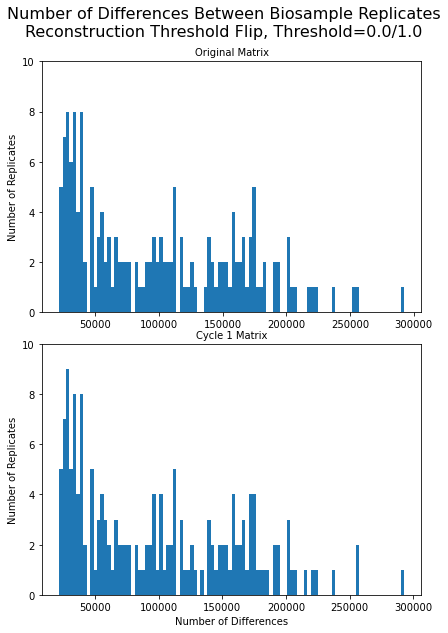

In [38]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()


axes[0].hist(cycle0_total_changes, bins=100)
axes[1].hist(cycle1_total_changes, bins=100)
axes[0].set_title('Original Matrix', fontsize=10)
axes[1].set_title('Cycle 1 Matrix', fontsize=10)
axes[0].set_ylim([0, 10])
axes[1].set_ylim([0, 10])
    

    
axes[1].set_xlabel('Number of Differences')
axes[0].set_ylabel('Number of Replicates')
axes[1].set_ylabel('Number of Replicates')
plt.suptitle('Number of Differences Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Number of Differences/Number of DHSs Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0')

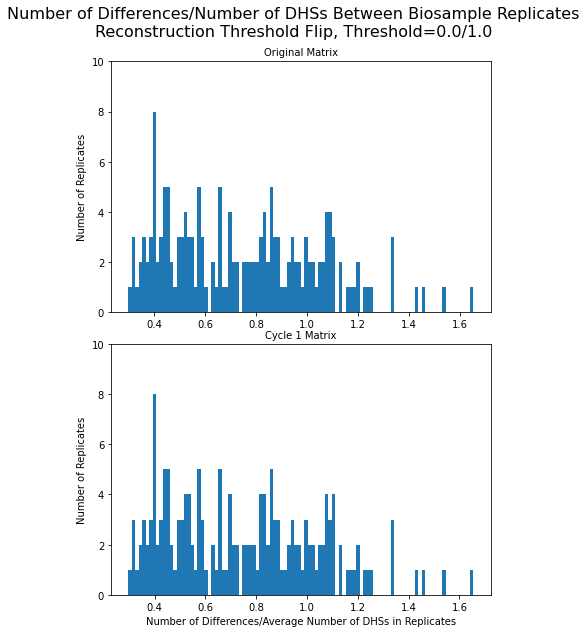

In [37]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes[0].hist(cycle0_percent_changes, bins=100)
axes[1].hist(cycle1_percent_changes, bins=100)
axes[0].set_title('Original Matrix', fontsize=10)
axes[1].set_title('Cycle 1 Matrix', fontsize=10)

axes[0].set_ylim([0, 10])
axes[1].set_ylim([0, 10])
  
axes[1].set_xlabel('Number of Differences/Average Number of DHSs in Replicates')
axes[0].set_ylabel('Number of Replicates')
axes[1].set_ylabel('Number of Replicates')
plt.suptitle('Number of Differences/Number of DHSs Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

In [55]:
def random_similarity(dhs_arr, iterations):
    total_changes = []
    for i in range(iterations):
        biosample1 = random.randrange(733)
        biosample2 = random.randrange(733)
        while biosample1==biosample2:
            biosample2 = random.randrange(733)
        changes = np.sum(np.abs(dhs_arr[biosample1, :] - dhs_arr[biosample2, :]))
        total_changes.append(changes)
    total_changes = np.array(total_changes)
    
    average_changes = np.mean(total_changes)
    print(average_changes)
    return total_changes

In [74]:
random_changes = random_similarity(cycle0_dhs_int_arr, 167)

138637.7724550898


In [75]:
random_changes

array([111584, 127772, 138758,  91243, 162040, 196378,  84382, 117103,
       158135, 261939, 292211, 262780, 108392,  90455,  48718, 136113,
       159407,  79731,  85451, 122835, 105952,  81145, 191781, 213526,
       432934,  68210, 110649,  66665, 115665,  51923, 161238,  38098,
        76065, 232864, 193968, 172945,  82698,  57014,  57263, 163954,
       298526,  40714,  80516,  84978,  60968, 208536, 185567,  45535,
       132646, 179126, 145106, 113545,  88444, 143974, 210199, 138195,
       114083, 109951,  99695, 236980,  48497,  97667,  88707, 184209,
       101143,  97483, 265610,  73320,  83773, 105400, 262132,  66692,
       121410,  94324, 227418,  85164, 121277,  52098, 104167, 222859,
       111032,  98995,  43607,  78394, 186360,  74216, 268342, 190687,
       150122, 308734,  98436, 168372, 187990,  61669,  59993, 204799,
        84838, 141305, 143166, 235019, 125962, 196778, 117690, 273735,
       102846, 112596,  67634,  94916, 101775, 213843, 167054, 161339,
      

In [79]:
cycle1_total_changes

array([ 60979,  61243,  24278,  76573,  56755,  28618,  67092,  86138,
        22373,  38931, 124874, 206506,  30329, 181014,  50522,  27031,
        29072,  29617, 139127,  28259, 156122, 255202, 190528,  51714,
        38613,  29499,  25463, 148751,  26609,  25729,  22398,  34266,
       161538,  92599, 202602,  35408, 152464, 116415,  38649, 173297,
       200544, 174810, 205268,  41496, 166480, 220690, 174413,  24480,
        95780, 101793, 106037,  23987, 101683, 184277, 110114, 140359,
       150993, 202839, 171032,  21380, 181631,  46922,  30790,  37064,
       193119,  32316,  88016,  27823,  27443,  23677, 124211,  37811,
        33891,  39575,  25516, 236486,  39547, 174392,  31137,  48080,
        27200,  33174, 146474, 222444,  45818,  33835,  73414,  56912,
       168857,  37704, 158084, 112666,  38042,  34449, 165643,  35772,
       256649,  47278, 157515, 167042, 160972, 162636, 171649,  97386,
        29982, 119846, 141114, 172939,  53355, 150875, 157810, 142585,
      

In [78]:
number_call_per_biosample = np.sum(cycle0_dhs_int_arr, axis=1)
np.mean(number_call_per_biosample)

104062.1241473397

**Replicate Sanity Check**

In [16]:
for i in range(len(biosamples_repnames)):
    rep = biosamples_repnames[i]
    if rep!='nan':
        samp_ind = np.where(biosamples_sampnames==rep)[0]
        if len(samp_ind)>0:
            samp_ind = samp_ind[0]
            samp_rep = biosamples_repnames[samp_ind]
            samp_rep_ind = np.where(biosamples_sampnames==samp_rep)[0]
            if len(samp_rep_ind)>0:
                samp_rep_ind = samp_rep_ind[0]
                if samp_rep_ind!=i:
                    print(samp_rep_ind, i)

In [67]:
total_changes = []
samp_rep_ind_list = []
count=0
tup_count=0
tup_list = []
for rep_name, rep_ind in zip(biosamples_repnames, range(len(biosamples_repnames))):
    if rep_name!='nan':
        if len(np.where(biosamples_sampnames==rep_name)[0]) == 1:
            samp_ind = np.where(biosamples_sampnames==rep_name)[0][0]
            if tuple(np.sort(np.array([rep_ind, samp_ind]))) not in samp_rep_ind_list:
                samp_rep_ind_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
                changes = np.sum(np.abs(cycle0_dhs_int_arr[rep_ind, :] - cycle0_dhs_int_arr[samp_ind, :]))
                total_changes.append(changes)
            else:
                tup_count+=1
                tup_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
        else:
            count+=1
total_changes = np.array(total_changes)
print(total_changes.shape)
average_changes = np.mean(total_changes)

(167,)


In [70]:
for i in samp_rep_ind_list:
    if i not in tup_list:
        print(i)

(56, 158)


In [66]:
tup_count

166

In [76]:
biosample_df.loc[[36, 37]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
36,37,HGF,NaN,ENCSR000ENS,ENCLB486ZZZ,ENCBS786ANZ,AG4192,LN2304,DS11738,DS11752,...,minElute,80.0,5.6,NaN,NaN,2009-08-05,22293070,0.4847,63915,63851
37,38,HGF,NaN,ENCSR000ENS,ENCLB487ZZZ,ENCBS310AAA,AG4191,LN2307,DS11752,DS11738,...,minElute,60.0,9.8,NaN,NaN,2009-08-05,351870884,0.4918,200730,200524


In [71]:
biosample_df.loc[[56, 158]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
56,57,CD34,Myeloid / erythroid,ENCSR191EII,ENCLB262HGC,ENCBS912YBQ,AG9156,LN2482,DS12274,DS14197,...,minElute,80.0,18.5,NaN,NaN,NaN,211609789,0.6518,196198,195691
158,159,CD34,NaN,ENCSR191EII,ENCLB323HYV,ENCBS912YBQ,AG9136,LN2999,DS14197,nan,...,minElute,160.0,8.1,6300000.0,Buffer A,NaN,24389674,0.6518,52106,52010


In [77]:
count + 167*2 - 1

349

In [31]:
biosamples_repnames[biosamples_repnames!='nan'].shape

(349,)